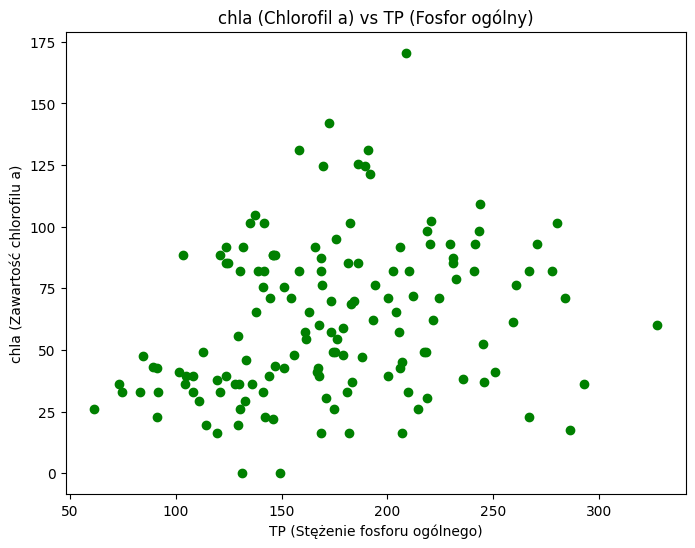

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as seabornInstance
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

# Wczytanie danych
dataset = pd.read_csv('Kruk_VLagun_156.csv', sep=';')

# Zamiana na format numeryczny z wymuszeniem NaN (coerce) dla 'TP' i 'chla'
dataset['TP'] = pd.to_numeric(dataset['TP'], errors='coerce')
dataset['chla'] = pd.to_numeric(dataset['chla'], errors='coerce')

# BARDZO WAŻNE: Usunięcie pustych wierszy z tych dwóch kolumn!
# Inaczej scikit-learn zwróci nam błąd podczas dopasowywania modelu.
dataset_clean = dataset.dropna(subset=['TP', 'chla'])

# --- WIZUALIZACJA DANYCH ---

# 1. Wykres rozrzutu (2D)
x1 = dataset_clean['TP']
y1 = dataset_clean['chla']
plt.figure(figsize=(8,6))
plt.scatter(x1, y1, color='green')
plt.title('chla (Chlorofil a) vs TP (Fosfor ogólny)')
plt.xlabel('TP (Stężenie fosforu ogólnego)')
plt.ylabel('chla (Zawartość chlorofilu a)')
plt.show()

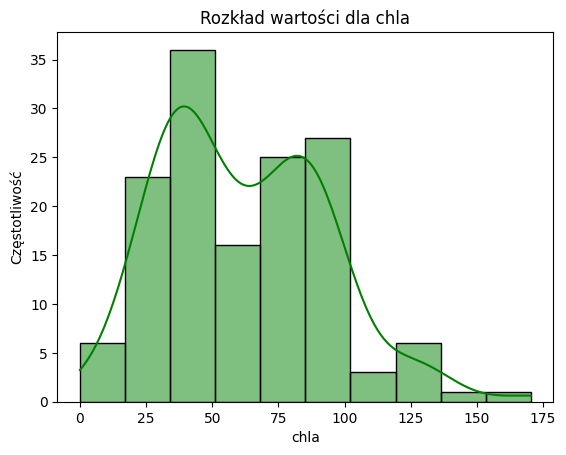

In [8]:
# 2. Histogram rozkładu dla 'chla'
plt.figure()
seabornInstance.histplot(dataset_clean['chla'], kde=True, color='green')
plt.title('Rozkład wartości dla chla')
plt.xlabel('chla')
plt.ylabel('Częstotliwość')
plt.show()

In [9]:
# --- PRZYGOTOWANIE DO UCZENIA MASZYNOWEGO ---

# Podział na zmienne (X = fosfor 'TP', y = chlorofil 'chla')
X = dataset_clean['TP'].values.reshape(-1,1)
y = dataset_clean['chla'].values.reshape(-1,1)

# Podział na zbiory treningowe (80%) i testowe (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Uczenie modelu Regresji Liniowej
regressor = LinearRegression()
regressor.fit(X_train, y_train)

# Wyświetlenie parametrów dopasowanej linii
print("Wartość przechwycenia (b):", regressor.intercept_[0])
print("Wartość nachylenia (a):", regressor.coef_[0][0])
print("\n")

Wartość przechwycenia (b): 35.828672182626974
Wartość nachylenia (a): 0.1432990972228281




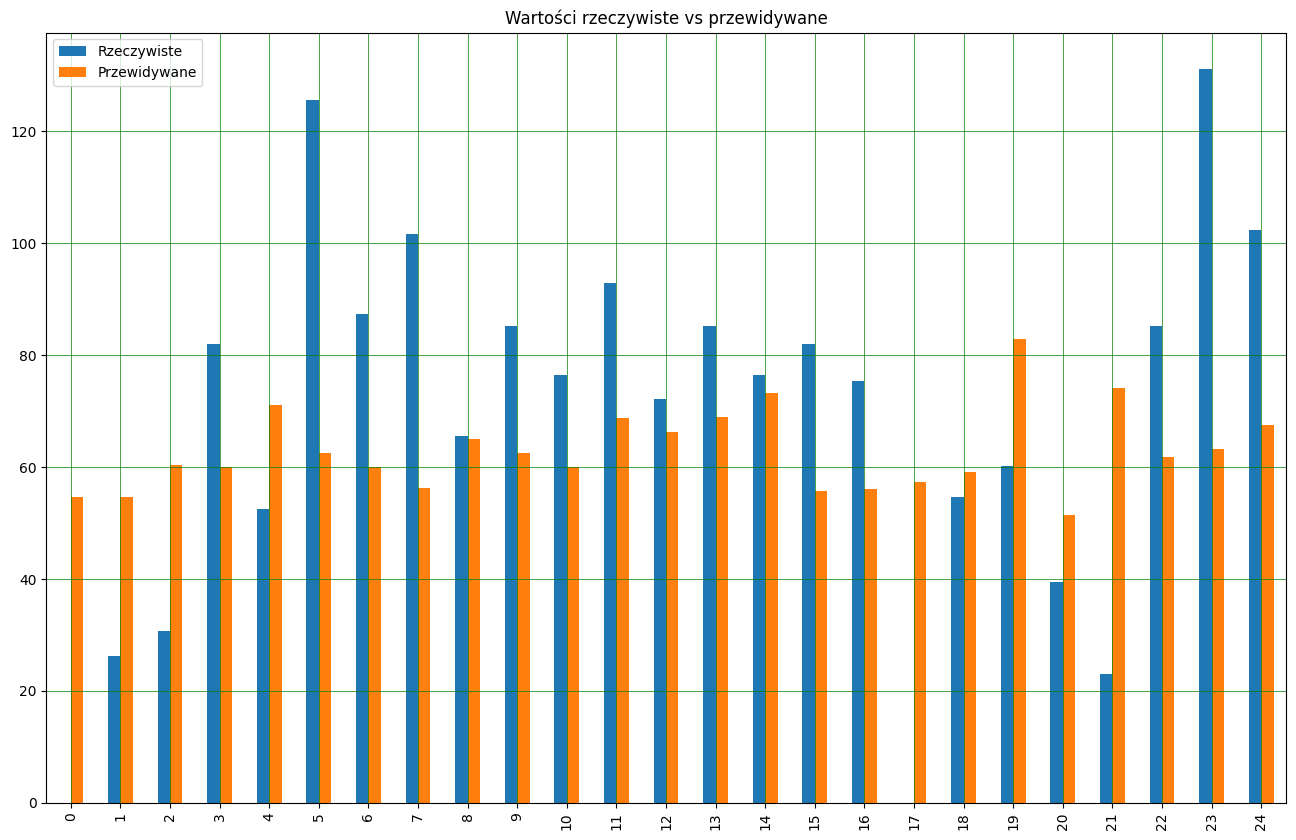

In [10]:
# --- TESTOWANIE I EWALUACJA ---

# Przewidywanie 'chla' na podstawie testowych wartości 'TP'
y_pred = regressor.predict(X_test)

# Stworzenie tabeli porównującej wartości rzeczywiste i przewidywane
df = pd.DataFrame({'Rzeczywiste': y_test.flatten(), 'Przewidywane': y_pred.flatten()})

# Wykres słupkowy dla 25 przewidywań
df1 = df.head(25)
df1.plot(kind='bar', figsize=(16,10))
plt.grid(which='major', linestyle='-', linewidth='0.5', color='green')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='black')
plt.title('Wartości rzeczywiste vs przewidywane')
plt.show()

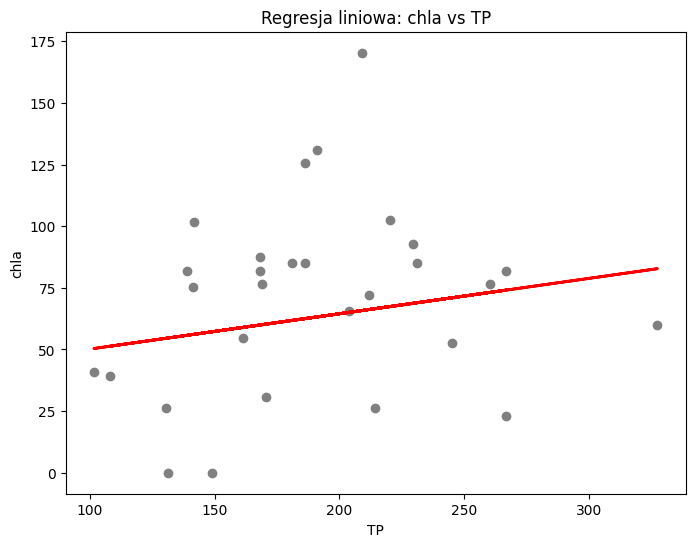

In [11]:
# Wykres narysowanej linii trendu (przewidywania) nałożonej na testowe punkty
plt.figure(figsize=(8,6))
plt.scatter(X_test, y_test, color='gray') # Rzeczywiste dane testowe na szaro
plt.plot(X_test, y_pred, color='red', linewidth=2) # Linia modelu na czerwono
plt.title('Regresja liniowa: chla vs TP')
plt.xlabel('TP')
plt.ylabel('chla')
plt.show()

In [12]:
# Obliczanie błędów
print('Mean Absolute Error (Średni błąd bezwzględny):', metrics.mean_absolute_error(y_test, y_pred))
print('Mean Squared Error (Błąd średniokwadratowy):', metrics.mean_squared_error(y_test, y_pred))
print('Root Mean Squared Error (Pierwiastek błędu średniokwadratowego):', np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

Mean Absolute Error (Średni błąd bezwzględny): 29.63876749491889
Mean Squared Error (Błąd średniokwadratowy): 1402.9852443283498
Root Mean Squared Error (Pierwiastek błędu średniokwadratowego): 37.456444630108045
